# Training Model Kesehatan Daun (sehat/sakit), CNN dari nol
Aturan penerimaan (dikunci sebelum training): macro F1 val ≥ 0,885 dan test ≥ 0,873.
Satu run. Test dijalankan sekali, hanya jika val lolos.

### Bagian 1 — Setup Colab

In [10]:
import tensorflow as tf

# 1. Mencetak versi TensorFlow
print(f"Versi TensorFlow: {tf.__version__}")

# 2. Menghentikan notebook dengan pesan jelas kalau GPU tidak ada
gpus = tf.config.list_physical_devices("GPU")
assert len(gpus) > 0, "GPU tidak ditemukan! Harap ganti runtime ke T4 GPU di menu Runtime > Change runtime type."

# 3. Mengatur seed tetap SEED = 42 agar hasilnya bisa direproduksi
SEED = 42
tf.keras.utils.set_random_seed(SEED)
print(f"Random seed diatur ke {SEED}")

Versi TensorFlow: 2.21.0
Random seed diatur ke 42


### Bagian 2 — Ambil data dari Drive

In [11]:
from google.colab import drive

# 1. Mount Drive, salin, dan ekstrak colab_bundle.zip
drive.mount("/content/drive")
!cp /content/drive/MyDrive/colab_bundle.zip /content/
!unzip -q -o /content/colab_bundle.zip -d /content/data_kesehatan

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
import pandas as pd
from pathlib import Path

# 2. Menyimpan path folder data ke variabel
DATA = Path("/content/data_kesehatan/data/processed")

# 3. Menghitung jumlah .jpg per split dan per kelas
total_jpg = 0
print("Jumlah citra per split dan kelas:")
for split in ["train", "val", "test"]:
    for label in ["sakit", "sehat"]:
        count = len(list((DATA / split / label).glob("*.jpg")))
        print(f"- {split}/{label}: {count}")
        total_jpg += count

# 4. Mencocokkan total .jpg dengan jumlah baris split.csv
df_split = pd.read_csv(DATA / "split.csv")
total_baris_csv = len(df_split)

print(f"\nTotal file .jpg: {total_jpg}")
print(f"Total baris di split.csv: {total_baris_csv}")

# Pakai assert agar notebook berhenti kalau tidak cocok
assert total_jpg == total_baris_csv, "Jumlah gambar JPG tidak sama dengan baris di CSV!"
assert total_jpg == 44739, f"Total data tidak sesuai ekspektasi (44739). Ditemukan: {total_jpg}"
print("Validasi data berhasil!")

Jumlah citra per split dan kelas:
- train/sakit: 22730
- train/sehat: 10593
- val/sakit: 4136
- val/sehat: 1572
- test/sakit: 4137
- test/sehat: 1571

Total file .jpg: 44739
Total baris di split.csv: 44739
Validasi data berhasil!


### Bagian 3 — Memuat data menjadi dataset TensorFlow

In [13]:
import tensorflow as tf

# 1. Mendefinisikan konstanta
CLASS_NAMES = ["sakit", "sehat"]
IMG_SIZE = 128
BATCH = 32

# 2. Memuat dataset
print("Memuat dataset training:")
train_raw = tf.keras.utils.image_dataset_from_directory(
    DATA / "train",
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=None, # None: per gambar agar bisa dishuffle dengan baik setelah di-cache
    shuffle=True,
    seed=SEED
)

print("\nMemuat dataset validasi:")
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA / "val",
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH,
    shuffle=False  # Tidak diacak untuk validasi
)

print("\nMemuat dataset testing:")
test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA / "test",
    labels="inferred",
    label_mode="int",
    class_names=CLASS_NAMES,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH,
    shuffle=False  # Tidak diacak untuk testing
)

# 3. Mencetak informasi
print(f"\nClass names: {train_raw.class_names}")
print(f"Jumlah file di val_ds: {len(val_ds.file_paths)}")


Memuat dataset training:
Found 33323 files belonging to 2 classes.

Memuat dataset validasi:
Found 5708 files belonging to 2 classes.

Memuat dataset testing:
Found 5708 files belonging to 2 classes.

Class names: ['sakit', 'sehat']
Jumlah file di val_ds: 5708


### Bagian 4 — Augmentasi dan normalisasi

Bentuk batch: (32, 128, 128, 3)
Nilai piksel minimum: 0.0000
Nilai piksel maksimum: 1.0000


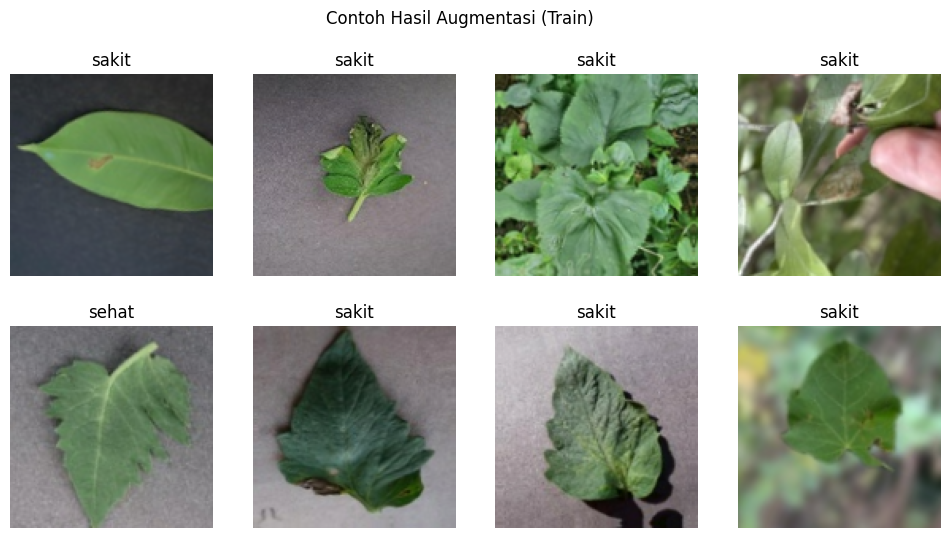

In [14]:
import matplotlib.pyplot as plt

# 1. Menyimpan paths sebelum map (karena file_paths akan hilang setelah .map)
val_paths = val_ds.file_paths
test_paths = test_ds.file_paths

# 2. Membuat layer augmentasi dan rescale
augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    tf.keras.layers.RandomRotation(0.1, seed=SEED),
    tf.keras.layers.RandomZoom(0.1, seed=SEED),
    tf.keras.layers.RandomContrast(0.1, seed=SEED),
])
rescale = tf.keras.layers.Rescaling(1.0 / 255)

# 3. Menerapkan optimasi cache, augment + rescale
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (train_raw
    .map(lambda x, y: (tf.cast(x, tf.uint8), y), num_parallel_calls=AUTOTUNE)  # hemat RAM
    .cache()                                    # decode sekali saja
    .shuffle(5000, seed=SEED)                   # acak ulang tiap epoch
    .batch(BATCH)
    .map(lambda x, y: (rescale(augment(tf.cast(x, tf.float32), training=True)), y),
         num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE))

val_ds = (val_ds
    .map(lambda x, y: (tf.cast(x, tf.uint8), y), num_parallel_calls=AUTOTUNE)
    .cache()
    .map(lambda x, y: (rescale(tf.cast(x, tf.float32)), y), num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE))

test_ds = (test_ds
    .map(lambda x, y: (tf.cast(x, tf.uint8), y), num_parallel_calls=AUTOTUNE)
    .cache()
    .map(lambda x, y: (rescale(tf.cast(x, tf.float32)), y), num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE))

# 4. Mengambil satu batch dari train_ds lalu mencetak nilai minimum dan maksimum piksel
for images, labels in train_ds.take(1):
    print(f"Bentuk batch: {images.shape}")
    print(f"Nilai piksel minimum: {tf.reduce_min(images).numpy():.4f}")
    print(f"Nilai piksel maksimum: {tf.reduce_max(images).numpy():.4f}")

    # Menampilkan 8 gambar train setelah augmentasi
    plt.figure(figsize=(12, 6))
    for i in range(8):
        ax = plt.subplot(2, 4, i + 1)
        # Clip values to [0, 1] for display
        plt.imshow(tf.clip_by_value(images[i], 0.0, 1.0))
        plt.title(CLASS_NAMES[labels[i]])
        plt.axis("off")
    plt.suptitle("Contoh Hasil Augmentasi (Train)")
    plt.show()


### Bagian 5 — Membangun CNN dari nol

In [15]:
from tensorflow.keras import layers, models
import numpy as np

# 1. Membuat fungsi build_model(num_classes=2)
def build_model(num_classes=2):
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = inputs

    # 4 blok: Conv -> BatchNorm -> ReLU -> MaxPool
    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
        x = layers.MaxPooling2D(2)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.4, seed=SEED)(x)
    x = layers.Dense(128, activation="relu")(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    return models.Model(inputs, outputs)

# 2. Memanggil model = build_model() lalu model.summary()
model = build_model()
model.summary()

# 3. Mengecek dengan assert bahwa jumlah parameter kurang dari 1 juta
total_params = model.count_params()
print(f"\nTotal parameter: {total_params}")
assert total_params < 1000000, "Jumlah parameter model melebihi 1 juta!"
assert total_params == 423010, f"Ekspektasi parameter 423.010, tapi mendapat {total_params}"

# 4. Mengecek output untuk input dummy
dummy_input = tf.zeros((2, 128, 128, 3))
dummy_output = model(dummy_input)
print(f"\nBentuk output dummy: {dummy_output.shape}")
assert dummy_output.shape == (2, 2), f"Bentuk output dummy salah: {dummy_output.shape}"

# Mengecek setiap barisnya berjumlah 1 (karena softmax)
sums = tf.reduce_sum(dummy_output, axis=1).numpy()
print(f"Jumlah probabilitas per baris: {sums}")
assert np.allclose(sums, [1.0, 1.0]), "Probabilitas keluaran softmax tidak berjumlah 1!"

print("\nValidasi Bagian 5 sukses!")

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,010 (1.61 MB)

 Trainable params: 422,050 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)


Total parameter: 423010

Bentuk output dummy: (2, 2)
Jumlah probabilitas per baris: [1. 1.]

Validasi Bagian 5 sukses!


### Bagian 6 — Training

In [16]:
import tensorflow as tf
from pathlib import Path

# 1. Buat folder output di Drive
OUT = Path("/content/drive/MyDrive/training_kesehatan")
OUT.mkdir(parents=True, exist_ok=True)

# 2. Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 3. Siapkan keempat callbacks
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=OUT / "best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    ),
    tf.keras.callbacks.CSVLogger(
        filename=OUT / "history.csv"
    )
]

# 4. Jalankan training
print("Memulai training...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=callbacks
)

Memulai training...
Epoch 1/50
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step - accuracy: 0.7154 - loss: 0.5468
Epoch 1: val_loss improved from None to 3.52436, saving model to /content/drive/MyDrive/training_kesehatan/best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/training_kesehatan/best.keras
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 146s 132ms/step - accuracy: 0.7510 - loss: 0.4853 - val_accuracy: 0.2812 - val_loss: 3.5244 - learning_rate: 0.0010
Epoch 2/50
1041/1042 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.8115 - loss: 0.3975
Epoch 2: val_loss improved from 3.52436 to 0.72860, saving model to /content/drive/MyDrive/training_kesehatan/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/training_kesehatan/best.keras
1042/1042 ━━━━━━━━━━━━━━━━━━━━ 131s 125ms/step - accuracy: 0.8190 - loss: 0.3809 - val_accuracy: 0.5175 - val_loss: 0.7286 - learning_rate: 0.0010
Epoch 3/50
1041/1042 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.8430 - loss: 0.3405
E

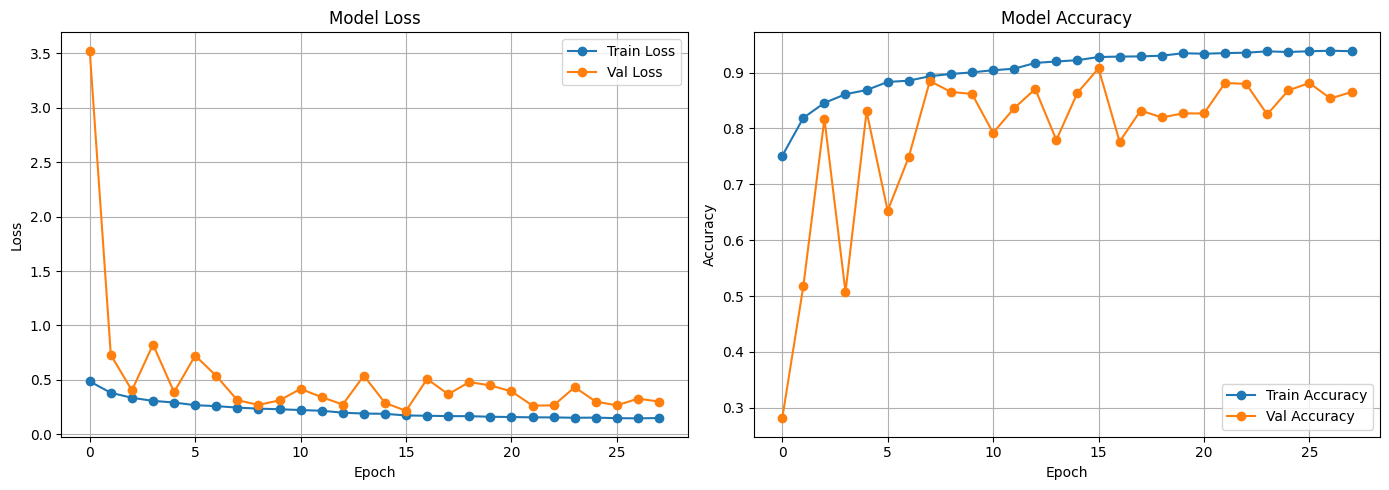

Grafik disimpan di /content/drive/MyDrive/training_kesehatan/history.png


In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# Membaca history dari CSV
history_df = pd.read_csv(OUT / "history.csv")

# Menggambar 2 grafik berdampingan
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Grafik Loss
ax1.plot(history_df['epoch'], history_df['loss'], label='Train Loss', marker='o')
ax1.plot(history_df['epoch'], history_df['val_loss'], label='Val Loss', marker='o')
ax1.set_title('Model Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

# Grafik Akurasi
ax2.plot(history_df['epoch'], history_df['accuracy'], label='Train Accuracy', marker='o')
ax2.plot(history_df['epoch'], history_df['val_accuracy'], label='Val Accuracy', marker='o')
ax2.set_title('Model Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

plt.tight_layout()

# Simpan gambar
plt.savefig(OUT / "history.png")
plt.show()
print(f"Grafik disimpan di {OUT / 'history.png'}")

### Bagian 7 — Evaluasi di data validasi

Memuat model terbaik dari Drive...
Melakukan prediksi pada data validasi...
Validasi panjang array sukses!

--- Classification Report ---
              precision    recall  f1-score   support

       sakit     0.9762    0.8943    0.9335      4136
       sehat     0.7723    0.9427    0.8490      1572

    accuracy                         0.9077      5708
   macro avg     0.8743    0.9185    0.8913      5708
weighted avg     0.9201    0.9077    0.9102      5708



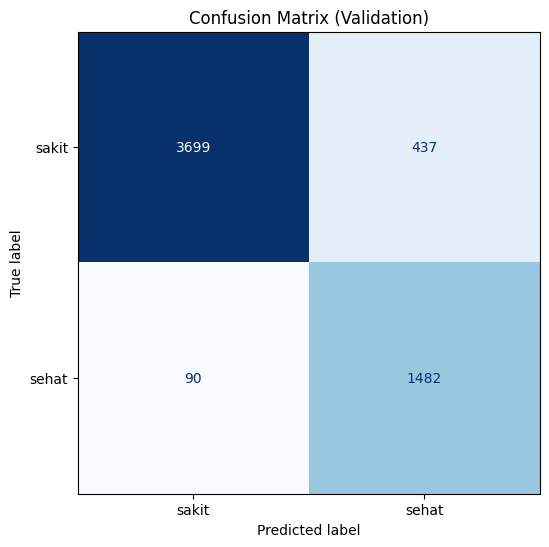

Confusion matrix disimpan di /content/drive/MyDrive/training_kesehatan/cm_val.png

--- Akurasi per Sumber Data ---
inat: 0.8047 (1536 gambar)
leaves: 0.9496 (674 gambar)
plantdoc: 0.7766 (385 gambar)
plantvillage: 0.9654 (3095 gambar)
rice: 1.0000 (18 gambar)

Macro F1: 0.8913
Status: LOLOS (≥ 0.885)


In [18]:
import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import classification_report, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Memuat model terbaik dari Drive
print("Memuat model terbaik dari Drive...")
model = tf.keras.models.load_model(OUT / "best.keras")

# 2. Mendapatkan y_pred, y_true, dan sumber
print("Melakukan prediksi pada data validasi...")
probs = model.predict(val_ds, verbose=0)
y_pred = probs.argmax(axis=1)
y_true = np.concatenate([y.numpy() for _, y in val_ds])
sumber = np.array([Path(p).name.split("__")[0] for p in val_paths])

# Memastikan panjangnya sesuai ekspektasi
assert len(y_pred) == 5708, f"Panjang y_pred = {len(y_pred)}"
assert len(y_true) == 5708, f"Panjang y_true = {len(y_true)}"
assert len(sumber) == 5708, f"Panjang sumber = {len(sumber)}"
print("Validasi panjang array sukses!\n")

# 3. Mencetak classification report
print("--- Classification Report ---")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

# 4. Menggambar dan menyimpan confusion matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix (Validation)")
plt.savefig(OUT / "cm_val.png")
plt.show()
print(f"Confusion matrix disimpan di {OUT / 'cm_val.png'}\n")

# 5. Mencetak akurasi per sumber
print("--- Akurasi per Sumber Data ---")
for s in np.unique(sumber):
    mask = (sumber == s)
    acc = np.mean(y_true[mask] == y_pred[mask])
    print(f"{s}: {acc:.4f} ({np.sum(mask)} gambar)")

# 6. Menghitung macro F1 dan mengecek aturan kelulusan
macro_f1 = f1_score(y_true, y_pred, average="macro")
print(f"\nMacro F1: {macro_f1:.4f}")

if macro_f1 >= 0.885:
    print("Status: LOLOS (≥ 0.885)")
else:
    print("Status: GAGAL (< 0.885)")


### Bagian 8 — Test (sekali saja)

Melakukan prediksi pada data test...
Validasi panjang array test sukses!

--- Classification Report (Test) ---
              precision    recall  f1-score   support

       sakit     0.9721    0.8932    0.9310      4137
       sehat     0.7682    0.9325    0.8424      1571

    accuracy                         0.9040      5708
   macro avg     0.8702    0.9128    0.8867      5708
weighted avg     0.9160    0.9040    0.9066      5708

Report disimpan di /content/drive/MyDrive/training_kesehatan/report_test.txt



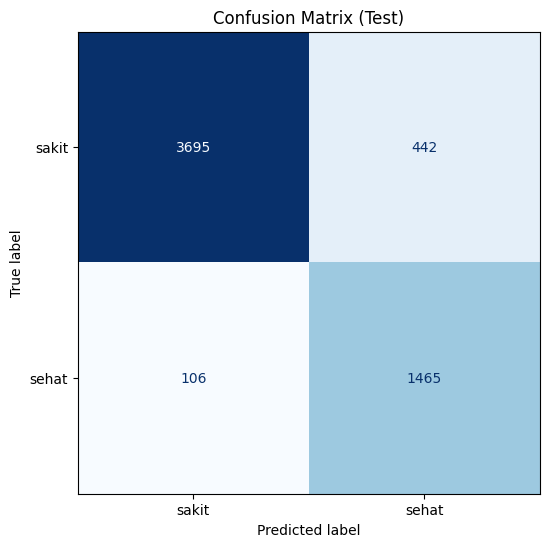

Confusion matrix test disimpan di /content/drive/MyDrive/training_kesehatan/cm_test.png

--- Akurasi per Sumber Data (Test) ---
inat: 0.8001 (1536 gambar)
leaves: 0.9497 (676 gambar)
plantdoc: 0.7377 (385 gambar)
plantvillage: 0.9657 (3093 gambar)
rice: 1.0000 (18 gambar)

Macro F1 Test: 0.8867
Status: LOLOS (≥ 0.873)


In [19]:
print("Melakukan prediksi pada data test...")
probs_test = model.predict(test_ds, verbose=0)
y_pred_test = probs_test.argmax(axis=1)
y_true_test = np.concatenate([y.numpy() for _, y in test_ds])
sumber_test = np.array([Path(p).name.split("__")[0] for p in test_paths])

# 1. Memastikan panjangnya sesuai ekspektasi
assert len(y_pred_test) == 5708, f"Panjang y_pred = {len(y_pred_test)}"
assert len(y_true_test) == 5708, f"Panjang y_true = {len(y_true_test)}"
assert len(sumber_test) == 5708, f"Panjang sumber = {len(sumber_test)}"
print("Validasi panjang array test sukses!\n")

# 2. Mencetak classification report dan menyimpan ke txt
report_text = classification_report(y_true_test, y_pred_test, target_names=CLASS_NAMES, digits=4)
print("--- Classification Report (Test) ---")
print(report_text)
(OUT / "report_test.txt").write_text(report_text)
print(f"Report disimpan di {OUT / 'report_test.txt'}\n")

# 3. Menggambar dan menyimpan confusion matrix
cm_test = confusion_matrix(y_true_test, y_pred_test)
disp_test = ConfusionMatrixDisplay(confusion_matrix=cm_test, display_labels=CLASS_NAMES)
fig, ax = plt.subplots(figsize=(6, 6))
disp_test.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix (Test)")
plt.savefig(OUT / "cm_test.png")
plt.show()
print(f"Confusion matrix test disimpan di {OUT / 'cm_test.png'}\n")

# 4. Mencetak akurasi per sumber
print("--- Akurasi per Sumber Data (Test) ---")
for s in np.unique(sumber_test):
    mask = (sumber_test == s)
    acc = np.mean(y_true_test[mask] == y_pred_test[mask])
    print(f"{s}: {acc:.4f} ({np.sum(mask)} gambar)")

# 5. Menghitung macro F1 dan mengecek aturan kelulusan
macro_f1_test = f1_score(y_true_test, y_pred_test, average="macro")
print(f"\nMacro F1 Test: {macro_f1_test:.4f}")

if macro_f1_test >= 0.873:
    print("Status: LOLOS (≥ 0.873)")
else:
    print("Status: GAGAL (< 0.873)")


### Bagian 9 — Ekspor model untuk backend

In [20]:
import json
import os

# 1. Konversi ke TFLite
print("Mengonversi model ke TFLite...")
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()
tflite_path = OUT / "kesehatan.tflite"
tflite_path.write_bytes(tflite_model)

# Cetak ukuran file
size_kb = os.path.getsize(tflite_path) / 1024
print(f"Ukuran kesehatan.tflite: {size_kb:.2f} KB")

# 2. Tulis label ke JSON
labels_path = OUT / "kesehatan_labels.json"
labels_path.write_text(json.dumps(CLASS_NAMES))
print(f"Label disimpan ke {labels_path}")

# 3. Verifikasi TFLite vs Keras
print("\nMemverifikasi hasil prediksi TFLite vs Keras...")
interp = tf.lite.Interpreter(model_path=str(tflite_path))
interp.allocate_tensors()
inp = interp.get_input_details()[0]
out = interp.get_output_details()[0]

# Ambil 1 batch dari val_ds
for images, labels in val_ds.take(1):
    # Prediksi dengan Keras
    keras_preds = model.predict(images, verbose=0)

    # Prediksi dengan TFLite
    tflite_preds = []
    for i in range(len(images)):
        x = tf.expand_dims(images[i], axis=0) # Tambahkan dimensi batch: (1, 128, 128, 3)
        interp.set_tensor(inp["index"], x)
        interp.invoke()
        p = interp.get_tensor(out["index"])[0]
        tflite_preds.append(p)
    tflite_preds = np.array(tflite_preds)

    # Cek selisih maksimum
    max_diff = np.max(np.abs(keras_preds - tflite_preds))
    print(f"Selisih maksimum Keras vs TFLite: {max_diff:.8e}")

    assert max_diff < 1e-4, f"Selisih terlalu besar: {max_diff}"
    print("Verifikasi sukses! Konversi TFLite aman dan sesuai.")


Mengonversi model ke TFLite...
Saved artifact at '/tmp/tmpqpmokyxa'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 2), dtype=tf.float32, name=None)
Captures:
  139740187241040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139740187239888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139740187240080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139740187240464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139740187239696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139740187238928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139740187238160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139740187238352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139740187237968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139740187239504: TensorSpec(shape=(), dtype=tf.resou

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Selisih maksimum Keras vs TFLite: 2.98023224e-07
Verifikasi sukses! Konversi TFLite aman dan sesuai.


In [21]:
# 1. Menghitung confidence dan array kebenaran
conf = probs.max(axis=1)
benar = (probs.argmax(axis=1) == y_true)

# 2. Mengecek performa pada berbagai threshold
print("--- Cek Ambang (Threshold) 'Tidak Yakin' di Data Validasi ---")
thresholds = [0.5, 0.6, 0.7, 0.8, 0.9]

for t in thresholds:
    mask_yakin = (conf >= t)
    jumlah_yakin = np.sum(mask_yakin)
    persen_yakin = jumlah_yakin / len(conf) * 100

    if jumlah_yakin > 0:
        akurasi_yakin = np.mean(benar[mask_yakin])
        print(f"Ambang {t:.1f}: {persen_yakin:.1f}% prediksi yakin | Akurasi tebakan yakin: {akurasi_yakin:.4f}")
    else:
        print(f"Ambang {t:.1f}: 0.0% prediksi yakin | Akurasi: N/A")

print("\n-> Silakan pilih ambang TERKECIL yang memiliki 'Akurasi tebakan yakin' >= 0.95")


--- Cek Ambang (Threshold) 'Tidak Yakin' di Data Validasi ---
Ambang 0.5: 100.0% prediksi yakin | Akurasi tebakan yakin: 0.9077
Ambang 0.6: 94.7% prediksi yakin | Akurasi tebakan yakin: 0.9273
Ambang 0.7: 89.2% prediksi yakin | Akurasi tebakan yakin: 0.9450
Ambang 0.8: 82.3% prediksi yakin | Akurasi tebakan yakin: 0.9642
Ambang 0.9: 71.8% prediksi yakin | Akurasi tebakan yakin: 0.9785

-> Silakan pilih ambang TERKECIL yang memiliki 'Akurasi tebakan yakin' >= 0.95


### Ringkasan hasil
- Epoch terbaik 16/28 (EarlyStopping). Macro F1 val 0,8913, macro F1 test 0,8867 (akurasi 0,904). LOLOS aturan penerimaan.
- Per sumber (test): PlantVillage 0,966, Leaves 0,950, iNaturalist 0,800, PlantDoc 0,738.
- Ambang "tidak yakin" = 0,80 (val: 82,3% tampil yakin, akurasi 0,964).
- Keterbatasan: model condong ke "sehat" (recall sakit 0,893); foto lapangan lebih sulit daripada foto studio.